**Purpose:** Imports libraries for frequency-domain filtering and visualization.

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

**Purpose:** Creates a matrix of distances from the frequency-domain center.

In [34]:
def distance_matrix(rows,cols):
    D = np.zeros((rows,cols))
    
    xc = rows//2
    yc = cols//2
    
    for i in range(rows):
        for j in range(cols):
            D[i][j] = np.sqrt((i-xc)**2+(j-yc)**2)
    return D

**Purpose:** Builds an ideal low-pass filter mask.

In [35]:
def ideal_lpf(D,D0):
    H = np.zeros(D.shape)
    H[D <= D0 ] = 1
    
    return H 

**Purpose:** Builds a Butterworth low-pass filter mask.

In [36]:
def butterworth_lpf(D,D0,n):
    return 1/(1+(D/D0)**(2*n))

**Purpose:** Builds a Gaussian low-pass filter mask.

In [37]:
def gaussian_lpf(D, D0):
    H = np.exp(-(D**2)/(2* D0**2))
    return H

    

**Purpose:** Applies a frequency-domain mask and converts the inverse transform to an image.

In [38]:
def apply_filter(img, H):
    F = np.fft.fft2(img)
    F = np.fft.fftshift(F)
    
    G = F * H
    
    G = np.fft.ifftshift(G)
    g = np.fft.ifft2(G)
    g = np.real(g)
    
    #normalize
    result = g- g.min()
    
    if result.max()>0:
        result = (result/result.max())*255
        
    
    return result.astype(np.uint8)
    

**Purpose:** Introduces the main filtering workflow.

## main Process


**Purpose:** Loads the grayscale image and creates its frequency-distance matrix.

In [39]:
import cv2
img = cv2.imread('../cat.jpg',0)
rows, cols = img.shape

#Cutoff frequency
D0 = 30
n = 2

D = distance_matrix(rows,cols)



**Purpose:** Creates ideal, Butterworth, and Gaussian low-pass masks.

In [40]:
H_ideal_low = ideal_lpf(D,D0)

H_butter_low = butterworth_lpf(D,D0,n)

H_gaussian_low = gaussian_lpf(D,D0)

**Purpose:** Derives the corresponding high-pass masks.

In [41]:
H_ideal_high = 1 - H_ideal_low

H_butter_high = 1 - H_butter_low

H_gaussian_high = 1 - H_gaussian_low

**Purpose:** Applies all low-pass and high-pass masks to the image.

In [42]:
ideal_low = apply_filter(img, H_ideal_low)
butter_low = apply_filter(img, H_butter_low)
gaussian_low = apply_filter(img, H_gaussian_low)

ideal_high = apply_filter(img, H_ideal_high)
butter_high = apply_filter(img, H_butter_high)
gaussian_high = apply_filter(img, H_gaussian_high)


**Purpose:** Displays the original image and all six filtered results.

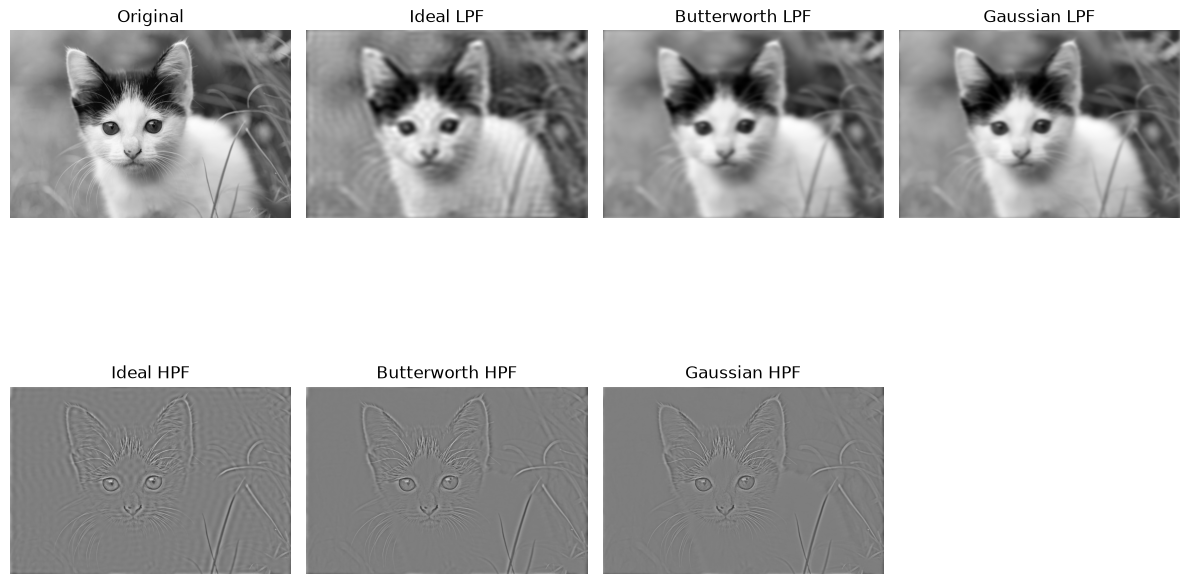

In [43]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(2, 4, 2)
plt.imshow(ideal_low, cmap='gray')
plt.title("Ideal LPF")
plt.axis("off")

plt.subplot(2, 4, 3)
plt.imshow(butter_low, cmap='gray')
plt.title("Butterworth LPF")
plt.axis("off")

plt.subplot(2, 4, 4)
plt.imshow(gaussian_low, cmap='gray')
plt.title("Gaussian LPF")
plt.axis("off")

plt.subplot(2, 4, 5)
plt.imshow(ideal_high, cmap='gray')
plt.title("Ideal HPF")
plt.axis("off")

plt.subplot(2, 4, 6)
plt.imshow(butter_high, cmap='gray')
plt.title("Butterworth HPF")
plt.axis("off")

plt.subplot(2, 4, 7)
plt.imshow(gaussian_high, cmap='gray')
plt.title("Gaussian HPF")
plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.